<a href="https://colab.research.google.com/github/MNMARQUES/Python/blob/main/Projeto04/Projeto04.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

# Importação das bibliotecas

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Carregamento da base Boston Housing
boston = fetch_openml(
    name="boston",
    version=1,
    as_frame=True
)

# Separação das variáveis de entrada e saída
X = boston.data.copy()
y = pd.to_numeric(boston.target)

# Garantir dados numéricos
X = X.apply(pd.to_numeric)

# Conferência da base
print("Dimensões das entradas:", X.shape)
print("Quantidade de registros:", len(y))
print("\nVariáveis disponíveis:")
print(X.columns.tolist())

print("\nPrimeiros registros:")
display(X.head())

print("\nEstatísticas da variável MEDV:")
print(y.describe())


Dimensões das entradas: (506, 13)
Quantidade de registros: 506

Variáveis disponíveis:
['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT']

Primeiros registros:


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33



Estatísticas da variável MEDV:
count    506.000000
mean      22.532806
std        9.197104
min        5.000000
25%       17.025000
50%       21.200000
75%       25.000000
max       50.000000
Name: MEDV, dtype: float64


In [2]:

# Separação entre treinamento e teste

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Dados de treinamento:", X_treino.shape)
print("Dados de teste:", X_teste.shape)

print("\nTotal de amostras:", len(X))
print("Amostras para treino:", len(X_treino))
print("Amostras para teste:", len(X_teste))


Dados de treinamento: (404, 13)
Dados de teste: (102, 13)

Total de amostras: 506
Amostras para treino: 404
Amostras para teste: 102


In [3]:

# Arquiteturas que serão comparadas

arquiteturas = {
    "MLP 16 neurônios": (16,),
    "MLP 32 neurônios": (32,),
    "MLP 64 neurônios": (64,),
    "MLP 32-16 neurônios": (32, 16)
}

resultados = []
modelos_treinados = {}

for nome, camadas in arquiteturas.items():

    modelo = Pipeline([
        ("escalador", StandardScaler()),
        ("rede_neural", MLPRegressor(
            hidden_layer_sizes=camadas,
            activation="relu",
            solver="adam",
            learning_rate_init=0.001,
            max_iter=3000,
            early_stopping=True,
            n_iter_no_change=40,
            random_state=42
        ))
    ])

    # Treinamento
    modelo.fit(X_treino, y_treino)

    # Previsões sobre dados que não participaram do treino
    previsoes = modelo.predict(X_teste)

    # Métricas de avaliação
    mae = mean_absolute_error(y_teste, previsoes)
    mse = mean_squared_error(y_teste, previsoes)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_teste, previsoes)

    resultados.append({
        "Modelo": nome,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R²": r2,
        "Épocas": modelo.named_steps[
            "rede_neural"
        ].n_iter_
    })

    modelos_treinados[nome] = modelo

# Tabela comparativa
df_resultados = pd.DataFrame(resultados)
df_resultados = df_resultados.sort_values(
    by="RMSE"
).reset_index(drop=True)

display(df_resultados.round(4))


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (3000) reached and the optimization hasn't converged yet.
  warnings.warn(


,Modelo,MAE,MSE,RMSE,R²,Épocas
0,MLP 64 neurônios,2.1837,10.8251,3.2901,0.8524,2239
1,MLP 16 neurônios,2.3167,12.8250,3.5812,0.8251,3000
2,MLP 32 neurônios,2.4796,13.5212,3.6771,0.8156,1279
3,MLP 32-16 neurônios,2.5532,14.5361,3.8126,0.8018,565


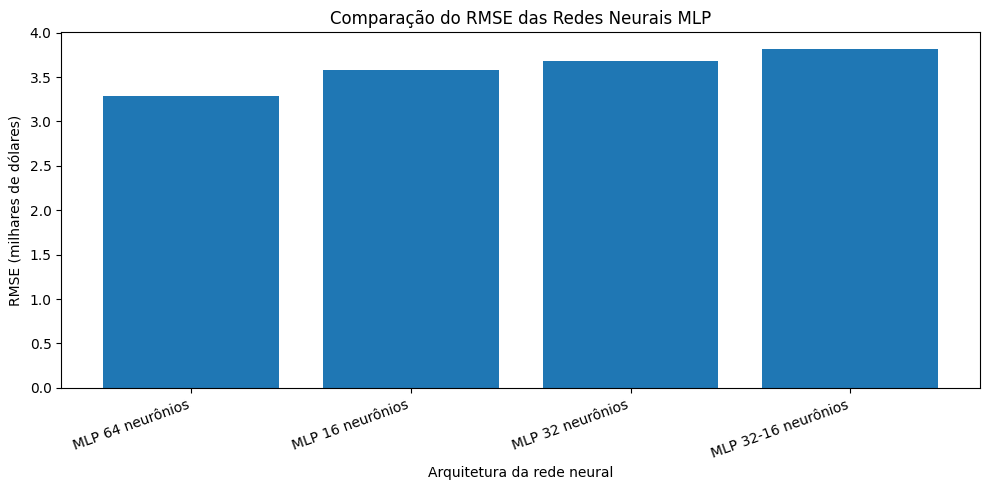

In [4]:

# Comparação do RMSE entre os modelos

plt.figure(figsize=(10, 5))

plt.bar(
    df_resultados["Modelo"],
    df_resultados["RMSE"]
)

plt.title("Comparação do RMSE das Redes Neurais MLP")
plt.xlabel("Arquitetura da rede neural")
plt.ylabel("RMSE (milhares de dólares)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


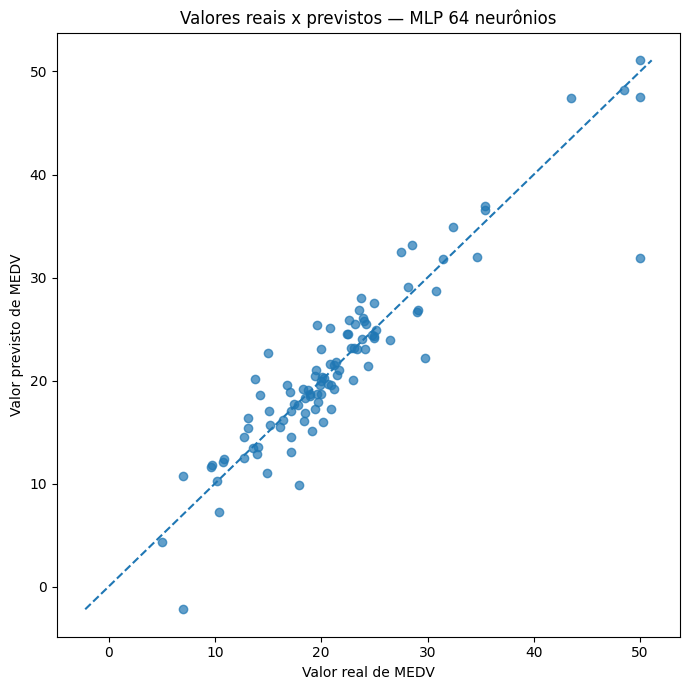

Melhor arquitetura: MLP 64 neurônios
RMSE: 3.2901
R²: 0.8524


In [5]:

# Seleção do modelo com menor RMSE

melhor_nome = df_resultados.iloc[0]["Modelo"]
melhor_modelo = modelos_treinados[melhor_nome]

previsoes_melhor = melhor_modelo.predict(X_teste)

plt.figure(figsize=(7, 7))

plt.scatter(
    y_teste,
    previsoes_melhor,
    alpha=0.7
)

limite_min = min(y_teste.min(), previsoes_melhor.min())
limite_max = max(y_teste.max(), previsoes_melhor.max())

plt.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    linestyle="--"
)

plt.title(f"Valores reais x previstos — {melhor_nome}")
plt.xlabel("Valor real de MEDV")
plt.ylabel("Valor previsto de MEDV")
plt.tight_layout()
plt.show()

print("Melhor arquitetura:", melhor_nome)
print(
    "RMSE:",
    round(df_resultados.iloc[0]["RMSE"], 4)
)
print(
    "R²:",
    round(df_resultados.iloc[0]["R²"], 4)
)


In [6]:

melhor = df_resultados.iloc[0]

print("ANÁLISE DOS RESULTADOS")
print("-" * 45)

print(f"Melhor modelo pelo RMSE: {melhor['Modelo']}")
print(f"MAE:  {melhor['MAE']:.4f}")
print(f"MSE:  {melhor['MSE']:.4f}")
print(f"RMSE: {melhor['RMSE']:.4f}")
print(f"R²:   {melhor['R²']:.4f}")

print("\nComparação entre arquiteturas:")
display(df_resultados.round(4))

if melhor["R²"] > 0:
    print(
        "\nO modelo apresentou capacidade explicativa "
        "positiva nos dados de teste."
    )
else:
    print(
        "\nO modelo não superou a referência de prever "
        "a média dos valores reais no conjunto de teste."
    )


ANÁLISE DOS RESULTADOS
---------------------------------------------
Melhor modelo pelo RMSE: MLP 64 neurônios
MAE:  2.1837
MSE:  10.8251
RMSE: 3.2901
R²:   0.8524

Comparação entre arquiteturas:


,Modelo,MAE,MSE,RMSE,R²,Épocas
0,MLP 64 neurônios,2.1837,10.8251,3.2901,0.8524,2239
1,MLP 16 neurônios,2.3167,12.8250,3.5812,0.8251,3000
2,MLP 32 neurônios,2.4796,13.5212,3.6771,0.8156,1279
3,MLP 32-16 neurônios,2.5532,14.5361,3.8126,0.8018,565



O modelo apresentou capacidade explicativa positiva nos dados de teste.
